# Image Classification with CIFAR-10 Dataset and Scikit-Learn

In this notebook, we will explore the basics of image classification using the CIFAR-10 dataset and build a simple image classifier using Scikit-Learn. We will perform the following steps:
1. Load and preprocess the CIFAR-10 dataset.
2. Extract features from the images.
3. Train a machine learning model on the extracted features.
4. Evaluate the model's performance.

## Step 1: Installing and Importing Libraries

### Installing Libraries

Before we start, we need to ensure that we have all the necessary libraries installed. We can use `!pip install` to install any missing libraries directly from the Jupyter Notebook. This command is useful for installing Python packages from the Python Package Index (PyPI).

### Why Install Libraries?

Libraries provide pre-written code that we can use to perform various tasks without having to write everything from scratch. Installing libraries ensures we have access to the necessary functions and tools needed for our project.

Here are the libraries we need for this notebook:
- **numpy:** For numerical operations.
- **matplotlib:** For plotting and visualizing images.
- **tensorflow:** For loading the CIFAR-10 dataset.
- **scikit-learn (sklearn):** For machine learning models and evaluation metrics.

### Installing Libraries Individually vs. All at Once


You can install each library separately by writing a `!pip install` command for each library. This looks like:
```python
!pip install numpy
!pip install matplotlib
!pip install tensorflow
!pip install scikit-learn


Alternatively, you can install all the libraries together in a single !pip install command by separating the library names with a space

!pip install numpy matplotlib tensorflow scikit-learn

## Differences and Considerations
- **Convenience**: Installing all libraries at once is more convenient and requires fewer lines of code. It can save time when writing and running the notebook.
- **Execution Time**: Running a single !pip install command can be faster than running multiple commands, as it reduces the overhead of initiating separate installation processes for each library.
- **Dependency Management**: Installing libraries together can help Pip resolve dependencies more efficiently, potentially avoiding conflicts that might arise when installing libraries separately.
- **Debugging**: Installing libraries individually can make it easier to identify which specific library caused an issue if an installation error occurs. However, this is generally only a concern if you encounter frequent installation problems.

For this notebook, we will install all necessary libraries together for convenience.

In [1]:
!pip install numpy matplotlib tensorflow scikit-learn


### Importing Libraries

After installing the libraries, we need to import them into our notebook. Importing libraries allows us to use their functionalities in our code. Each library is imported using an alias (short name) to make the code cleaner and more readable.

Let's import the required libraries:


In [2]:
# Importing necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score


## Step 2: Loading and Preprocessing the CIFAR-10 Dataset

The CIFAR-10 dataset is readily available in the `keras` library. We will load the dataset and preprocess it by converting the images to grayscale and flattening them.


In [3]:
# Load CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# To minimize computational demands lets work with three classes of your choice

# CIFAR-10 classes
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']


# Choose a subset of classes
chosen_classes = ['cat', 'dog', 'ship']
class_indices = [class_names.index(cls) for cls in chosen_classes]

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 633s 4us/step


In [4]:
# Filter data for the chosen classes
mask_train = np.isin(y_train, class_indices)
mask_test = np.isin(y_test, class_indices)
X_train_subset = X_train[mask_train.flatten()]
y_train_subset = y_train[mask_train]
X_test_subset = X_test[mask_test.flatten()]
y_test_subset = y_test[mask_test]


In [5]:
# Convert images to grayscale
X_train_gray = np.dot(X_train_subset[...,:3], [0.2989, 0.5870, 0.1140])
X_test_gray = np.dot(X_test_subset[...,:3], [0.2989, 0.5870, 0.1140])

# Normalize the images
X_train_normalized = X_train_gray / 255.0
X_test_normalized = X_test_gray / 255.0

# Flatten the images
X_train_flat = X_train_normalized.reshape(X_train_normalized.shape[0], -1)
X_test_flat = X_test_normalized.reshape(X_test_normalized.shape[0], -1)




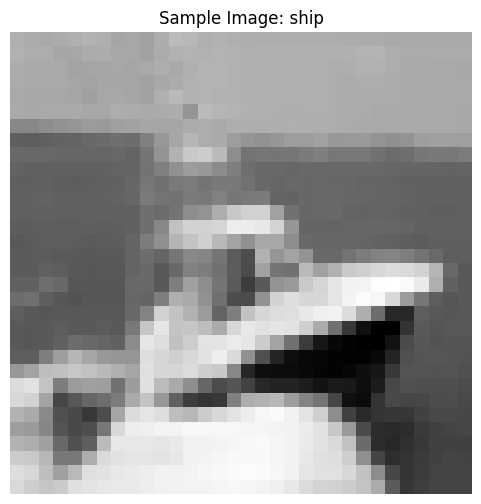

Training set size: (15000, 1024)
Testing set size: (3000, 1024)


In [6]:
# Display a sample image
plt.figure(figsize=(6, 6))
plt.imshow(X_train_gray[0], cmap='gray')
plt.title(f'Sample Image: {chosen_classes[np.where(class_indices == y_train_subset[0])[0][0]]}')
plt.axis('off')
plt.show()

print("Training set size:", X_train_flat.shape)
print("Testing set size:", X_test_flat.shape)

## Step 3: Training a Machine Learning Model

### What is SVM (Support Vector Machine)?

Support Vector Machine (SVM) is a supervised machine learning algorithm that can be used for both classification and regression tasks. However, it is mostly used for classification problems. The objective of the SVM algorithm is to find a hyperplane in an N-dimensional space (N is the number of features) that distinctly classifies the data points.

### Key Concepts:

- **Hyperplane:** A decision boundary that separates different classes in the feature space. In 2D, it's a line; in 3D, it's a plane.
- **Support Vectors:** Data points that are closest to the hyperplane and influence its position and orientation. These points help in maximizing the margin of the classifier.
- **Margin:** The distance between the hyperplane and the closest data points from either class. SVM aims to maximize this margin.

### Why Use SVM?

- **Effective in high-dimensional spaces:** SVM is very effective when the number of features is large.
- **Memory efficient:** It uses a subset of training points (support vectors) in the decision function, making it memory efficient.
- **Versatile:** Different kernel functions can be specified for the decision function. Common kernels include linear, polynomial, and radial basis function (RBF).

### What does `SVC(kernel='linear')` mean?

`SVC` stands for Support Vector Classification, which is a class in the Scikit-Learn library used to implement the SVM algorithm for classification tasks. The `kernel` parameter in the `SVC` class specifies the type of hyperplane used to separate the data.

#### Kernel Types:

- **Linear Kernel:** The data is linearly separable (i.e., a straight line or hyperplane can separate the data). This is the simplest kernel.
  - When we use `SVC(kernel='linear')`, it means we are using a linear kernel for our SVM. This kernel is appropriate when the data can be separated by a straight line (or hyperplane in higher dimensions).
- **Polynomial Kernel:** The data is not linearly separable, but a polynomial function of the input features can separate the data.
- **Radial Basis Function (RBF) Kernel:** The data is not linearly separable, but mapping the data into a higher-dimensional space using a Gaussian (RBF) function can separate the data.

### Training the SVM Model

We will use a Support Vector Machine (SVM) classifier from Scikit-Learn to train our model on the extracted features.


In [7]:
# Train an SVM classifier
model = SVC(kernel='linear')
model.fit(X_train_flat, y_train_subset.ravel())

# Predict on the test set
y_pred = model.predict(X_test_flat)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test_subset, y_pred))
print("Classification Report:\n", classification_report(y_test_subset, y_pred, target_names=chosen_classes))




Accuracy: 0.547
Classification Report:
               precision    recall  f1-score   support

         cat       0.48      0.48      0.48      1000
         dog       0.49      0.48      0.49      1000
        ship       0.66      0.68      0.67      1000

    accuracy                           0.55      3000
   macro avg       0.54      0.55      0.55      3000
weighted avg       0.54      0.55      0.55      3000



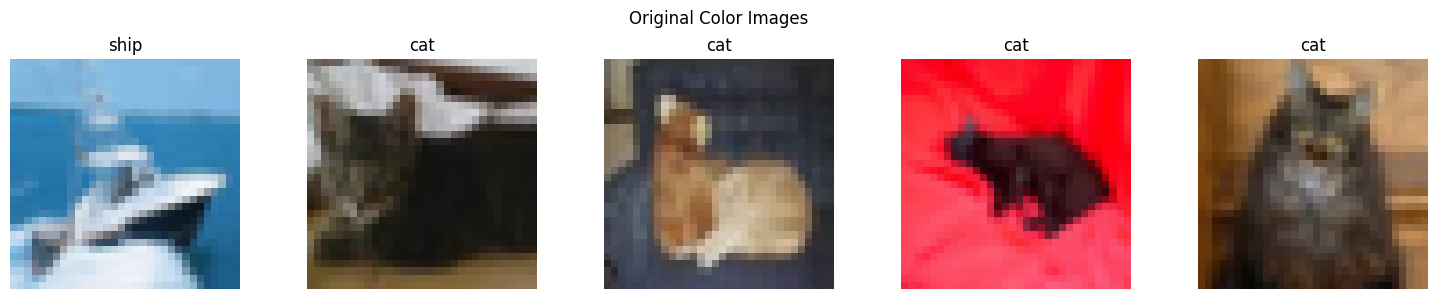

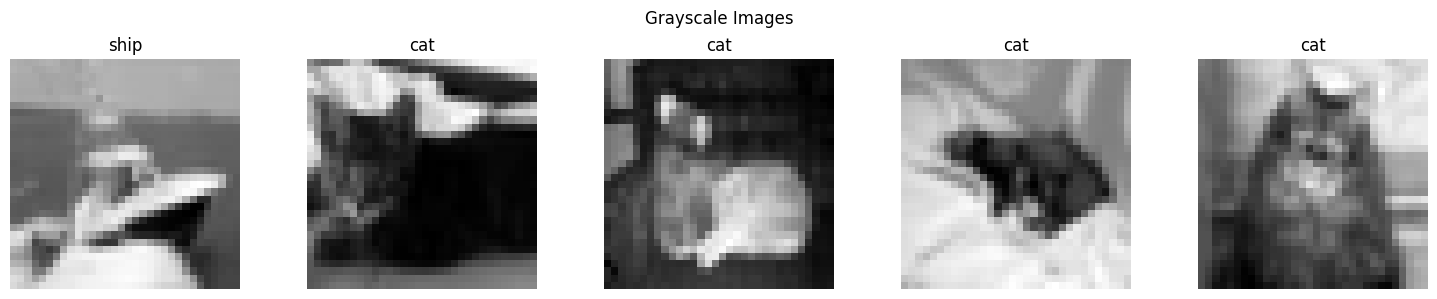

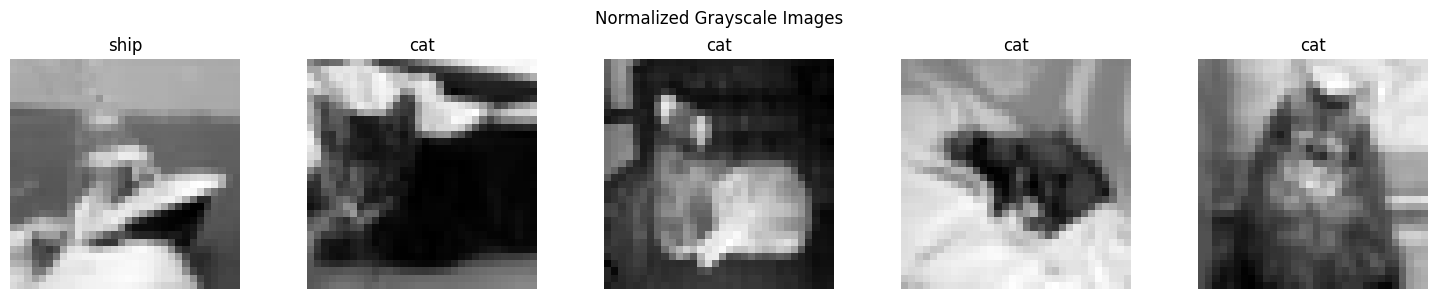

In [8]:
# Lets see some images of the  datasset in the different stages
# Function to display images
def display_images(images, titles, main_title, cmap=None):
    fig, axes = plt.subplots(1, 5, figsize=(15, 3))
    fig.suptitle(main_title)
    for i, ax in enumerate(axes):
        if cmap:
            ax.imshow(images[i], cmap=cmap)
        else:
            ax.imshow(images[i])
        ax.set_title(titles[i])
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# Display original color images
display_images(X_train_subset[:5],
               [chosen_classes[np.where(class_indices == y)[0][0]] for y in y_train_subset[:5]],
               'Original Color Images')

# Display grayscale images
display_images(X_train_gray[:5],
               [chosen_classes[np.where(class_indices == y)[0][0]] for y in y_train_subset[:5]],
               'Grayscale Images', cmap='gray')

# Display normalized images
display_images(X_train_normalized[:5],
               [chosen_classes[np.where(class_indices == y)[0][0]] for y in y_train_subset[:5]],
               'Normalized Grayscale Images', cmap='gray')

### Visualizing Model Predictions

To better understand the SVM's performance, I displayed several test images together with their true labels and the labels predicted by the model. This makes it easier to see which images the classifier recognizes correctly and where it makes mistakes. Comparing the predictions visually also helps connect the numerical evaluation results to the actual image classification task.

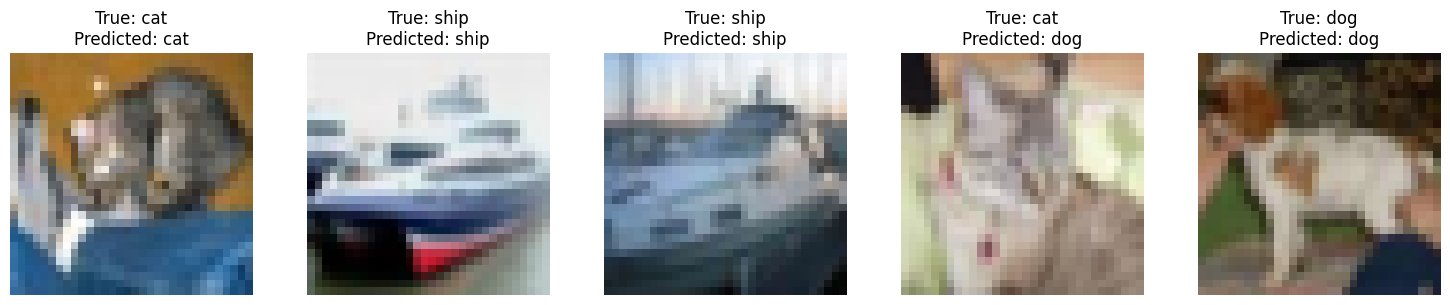

In [9]:
# Display sample predictions with their true labels
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for i, ax in enumerate(axes):
    # Show the test image
    ax.imshow(X_test_subset[i])

    # Get the true and predicted class names
    true_label = class_names[y_test_subset[i].item()]
    predicted_label = class_names[y_pred[i]]

    # Display both labels above the image
    ax.set_title(f"True: {true_label}\nPredicted: {predicted_label}")
    ax.axis('off')

plt.tight_layout()
plt.show()

## Step 4: My Experiments

After completing the original SVM model, I tested three changes to see how different choices affect image classification. I compared linear and RBF kernels, changed the C parameter, and reduced the amount of training data. For each experiment, I kept the comparison conditions as consistent as possible so I could see how each individual change affected the model's accuracy.

### Experiment 1: Comparing Linear and RBF Kernels

The original model used a linear kernel. For this experiment, I compared a linear kernel with an RBF kernel using the same smaller sample of 3,000 training images. Using the smaller sample made the RBF model more practical to train while still allowing a fair comparison between the two kernels.

In [10]:
# Experiment 1: Compare Linear and RBF kernels on the same smaller sample

# Select a balanced sample of 3,000 training images
X_exp1, _, y_exp1, _ = train_test_split(
    X_train_flat,
    y_train_subset.ravel(),
    train_size=3000,
    random_state=42,
    stratify=y_train_subset.ravel()
)

# Train a Linear SVM
linear_exp1 = SVC(kernel='linear')
linear_exp1.fit(X_exp1, y_exp1)

# Train an RBF SVM
rbf_model = SVC(kernel='rbf')
rbf_model.fit(X_exp1, y_exp1)

# Make predictions on the same test set
y_pred_linear_exp1 = linear_exp1.predict(X_test_flat)
y_pred_rbf = rbf_model.predict(X_test_flat)

# Calculate accuracy for both models
linear_exp1_accuracy = accuracy_score(y_test_subset, y_pred_linear_exp1)
rbf_accuracy = accuracy_score(y_test_subset, y_pred_rbf)

print(f"Linear SVM Accuracy: {linear_exp1_accuracy:.4f}")
print(f"RBF SVM Accuracy: {rbf_accuracy:.4f}")
print(f"Difference: {rbf_accuracy - linear_exp1_accuracy:+.4f}")

Linear SVM Accuracy: 0.5067
RBF SVM Accuracy: 0.6200
Difference: +0.1133


**Observation:** The RBF kernel reached an accuracy of 62.00%, compared with 50.67% for the linear kernel on the same 3,000 training images. This suggests that a nonlinear decision boundary worked better for separating cats, dogs, and ships in this experiment. The result shows that kernel choice can have a noticeable effect on image classification performance.

### Experiment 2: Changing the C Parameter

The original Linear SVM used the default C value of 1.0. For this experiment, I lowered C to 0.1 while keeping the linear kernel and the same training and testing data. This experiment tests whether stronger regularization changes the model's image classification accuracy.

In [11]:
# Experiment 2: Train a Linear SVM with a smaller C value

# Calculate the accuracy of the original model for comparison
baseline_accuracy = accuracy_score(y_test_subset.ravel(), y_pred)

# Train a Linear SVM with C = 0.1
c_model = SVC(kernel='linear', C=0.1)
c_model.fit(X_train_flat, y_train_subset.ravel())

# Make predictions
y_pred_c = c_model.predict(X_test_flat)

# Calculate accuracy
c_accuracy = accuracy_score(y_test_subset.ravel(), y_pred_c)

# Compare the results
print(f"Original Linear SVM (C=1.0) Accuracy: {baseline_accuracy:.4f}")
print(f"Linear SVM (C=0.1) Accuracy: {c_accuracy:.4f}")
print(f"Difference: {c_accuracy - baseline_accuracy:+.4f}")

Original Linear SVM (C=1.0) Accuracy: 0.5470
Linear SVM (C=0.1) Accuracy: 0.5593
Difference: +0.0123


**Observation:** Lowering C from 1.0 to 0.1 increased the accuracy from 54.70% to 55.93%. The improvement was small, but it showed that changing the regularization strength can affect how well the SVM generalizes to new images. In this case, the smaller C value performed slightly better than the default value.

### Experiment 3: Using Less Training Data

For the third experiment, I trained the same linear SVM using only half of the original training data. This allowed me to test how the amount of training data affects image classification performance.

In [12]:
# Experiment 3: Use only half of the training data
X_half, _, y_half, _ = train_test_split(
    X_train_flat,
    y_train_subset.ravel(),
    train_size=0.5,
    random_state=42,
    stratify=y_train_subset.ravel()
)

print("Original number of training images:", X_train_flat.shape[0])
print("Experiment training images:", X_half.shape[0])

# Train the same linear SVM on the smaller training set
half_model = SVC(kernel='linear')
half_model.fit(X_half, y_half)

# Make predictions using the same full test set
y_pred_half = half_model.predict(X_test_flat)

# Calculate accuracy
half_accuracy = accuracy_score(y_test_subset, y_pred_half)

print(f"\nOriginal Linear SVM Accuracy: {baseline_accuracy:.4f}")
print(f"Half Training Data Accuracy: {half_accuracy:.4f}")
print(f"Difference: {half_accuracy - baseline_accuracy:+.4f}")

Original number of training images: 15000
Experiment training images: 7500

Original Linear SVM Accuracy: 0.5470
Half Training Data Accuracy: 0.5277
Difference: -0.0193


**Observation:** Using only half of the training data reduced the accuracy from 54.70% to 52.77%. This result suggests that the additional training examples helped the SVM recognize patterns across the three image classes. It also showed me how the amount of training data can influence computer vision performance.

### Comparison of Experiment Results

The chart below summarizes the accuracy results from the original model and the three experiments. The training-set size is included where it changed so that the results can be interpreted correctly.

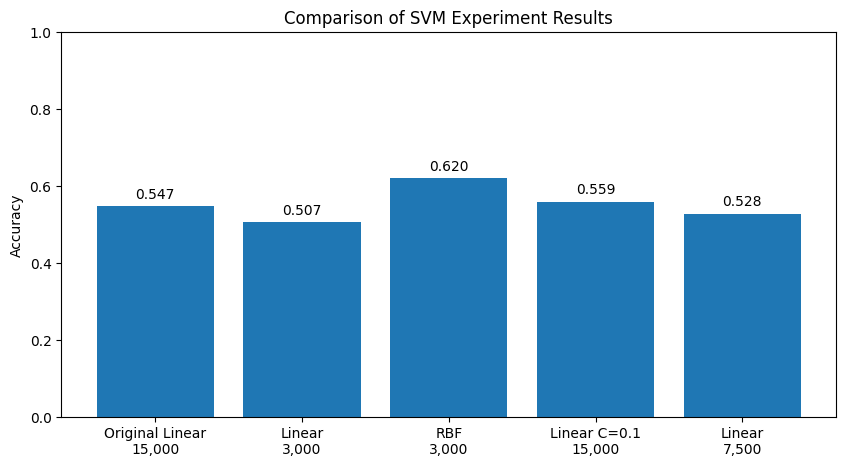

In [13]:
# Compare the original model with all experiment results
experiment_names = [
    'Original Linear\n15,000',
    'Linear\n3,000',
    'RBF\n3,000',
    'Linear C=0.1\n15,000',
    'Linear\n7,500'
]

experiment_accuracies = [
    baseline_accuracy,
    linear_exp1_accuracy,
    rbf_accuracy,
    c_accuracy,
    half_accuracy
]

plt.figure(figsize=(10, 5))
bars = plt.bar(experiment_names, experiment_accuracies)

plt.ylabel('Accuracy')
plt.title('Comparison of SVM Experiment Results')
plt.ylim(0, 1)

# Display the accuracy above each bar
for bar, accuracy in zip(bars, experiment_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f'{accuracy:.3f}',
        ha='center'
    )

plt.show()

### What I Learned from My Experiments

The additional experiments helped me understand how different choices can affect an SVM's performance in image classification. The RBF kernel performed better than the Linear kernel on the same 3,000-image sample, which showed me that a nonlinear decision boundary can work better for more complex image data. Lowering C from 1.0 to 0.1 slightly improved the full-data model, while reducing the amount of training data lowered the accuracy. I also found the true-versus-predicted visualization useful because it connected the numerical results to actual computer vision decisions and made the model's mistakes easier to understand.

## Step 5: Conclusion

In this notebook, we:
1. Loaded and preprocessed the CIFAR-10 dataset.
2. Converted the images to grayscale and flattened them to use as features.
3. Trained an SVM classifier on the extracted features.
4. Evaluated the model's performance.

### Summary of SVM

Support Vector Machines (SVM) are a powerful tool for classification tasks. They work by finding the optimal hyperplane that maximizes the margin between different classes. The key points include:
- **Hyperplane:** The decision boundary.
- **Support Vectors:** Critical data points that define the hyperplane.
- **Margin:** The gap between the hyperplane and the nearest data points from any class.

SVMs are effective in high-dimensional spaces and are versatile due to the use of different kernel functions. However, they can be computationally intensive for large datasets and less effective for overlapping classes.

This exercise provided a basic introduction to image classification using classical machine learning techniques. Next  few modules will explore advanced applications, using deep learning models like Convolutional Neural Networks (CNNs) using libraries such as TensorFlow or PyTorch.
